<a href="https://colab.research.google.com/github/laoneya31/IAT360-Group-18/blob/main/notebooks/Daksh_Setup_Baseline_BatchSize.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1><b>Fruit Freshness Detection Using YOLO</b></h1></center>
<center>IAT 360 Group 18: training environment, baseline and batch size (Daksh)</center>

Grocery stores lose money when rotting produce goes unnoticed in display bins and spreads spoilage to nearby fruit. This
project fine-tunes a pretrained YOLOv8 model to detect every apple, banana and orange in a cluttered scene and flag the
rotten ones. It is a **supervised object detection** problem, and the model could run on a camera above a produce display
or a back-room sorting table.

This notebook covers my part of the project:

| Task | Section |
|---|---|
| Training environment: YOLO repo cloned, Colab GPU, shared training script | 1 |
| Quick test training on a small subset, to catch format errors early | 2 to 4 |
| Train and save the baseline, and share its results | 5 |
| Tune batch size at 3 values and compare with the baseline | 6 |
| Export YOLO plots and confusion matrices into one folder | 7 |
| Shortcomings and challenges notes for the report | 8 |

**Real data or practice data.** Sections 5 to 7 use the group dataset as soon as Philip's `fruit_freshness.zip` is on
Drive. Until then they run a **rehearsal** on the small practice set from Section 3, with tiny settings, only to prove the
code works. Rehearsal numbers are not results and must not go in the report.

# 1. Environment

Use a GPU runtime: **Runtime > Change runtime type > T4 GPU**. The shared Drive folder must be in your My Drive: right-click `IAT360-Group 18` in *Shared with me* and choose **Organize > Add shortcut**.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Clone our repo and the official YOLO repo. YOLO is pinned to one release so all four members train with identical code.

In [ ]:
import os, sys
REPO = "/content/IAT360-Group-18"
YOLO_TAG = "v8.4.204"

if os.path.exists(REPO):
    !git -C {REPO} pull --ff-only
else:
    !git clone https://github.com/laoneya31/IAT360-Group-18 {REPO}
# The folder must not be called "ultralytics": /content is on sys.path, so it would hide the real package.
if not os.path.exists("/content/yolo_repo"):
    !git -c advice.detachedHead=false clone -q --depth 1 --branch {YOLO_TAG} https://github.com/ultralytics/ultralytics /content/yolo_repo
%pip install -q /content/yolo_repo kagglehub
%cd {REPO}

Cloning into '/content/IAT360-Group-18'...
remote: Enumerating objects: 105, done.
remote: Counting objects: 100% (105/105), done.
remote: Compressing objects: 100% (71/71), done.
remote: Total 105 (delta 56), reused 71 (delta 25), pack-reused 0 (from 0)
Receiving objects: 100% (105/105), 82.35 KiB | 2.17 MiB/s, done.
Resolving deltas: 100% (56/56), done.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
/content/IAT360-Group-18


Importing required libraries, and checking the software and hardware.

In [ ]:
import glob, hashlib, random, shutil
import cv2
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

import ultralytics
ultralytics.checks()
from ultralytics import YOLO

sys.path.insert(0, f"{REPO}/src")
import fruit_yolo as fy

fy.check_config()
print("Team Drive folder:", fy.find_team_drive())
print("Baseline settings:", fy.BASELINE)

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/235.7 GB disk)
config.yaml: 6 classes, order matches.
Team Drive folder: /content/drive/MyDrive/IAT360-Group 18
Baseline settings: {'model': 'yolov8s.pt', 'epochs': 50, 'patience': 20, 'imgsz': 640, 'batch': 16, 'optimizer': 'AdamW', 'lr0': 0.001, 'momentum': 0.9, 'warmup_bias_lr': 0.0, 'seed': 0, 'deterministic': True}


# 2. Dataset Description

The group dataset has six classes. They combine the fruit type with its freshness, following our
[labelling rules](https://github.com/laoneya31/IAT360-Group-18/blob/main/docs/LABELLING_RULES.md).

In [ ]:
class_labels = dict(enumerate(fy.CLASS_NAMES))
class_labels

{0: 'fresh_apple',
 1: 'fresh_banana',
 2: 'fresh_orange',
 3: 'rotten_apple',
 4: 'rotten_banana',
 5: 'rotten_orange'}

**Labelling format.** Each image has one `.txt` file with one row per object:

    class_id x_center y_center width height

All four box values are normalised to between 0 and 1, relative to the image size.

**Folder hierarchy.** YOLO expects images and labels in matching folders, and this layout is already in our repo:

    datasets/fruit_freshness/
      images/train   images/val   images/test
      labels/train   labels/val   labels/test

**Where the data comes from.** Public datasets are used for training and validation. Our own 120 photos, 30 per member,
are held out as the test set. Sources are listed in
[DATA_SOURCES.md](https://github.com/laoneya31/IAT360-Group-18/blob/main/docs/DATA_SOURCES.md).

**Practice set for the quick test.** To test the pipeline before the group dataset is ready, I build a small multi-fruit
set in the same format from the Kaggle
[Fruits fresh and rotten](https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification) images. It
is regenerated on each run and is never committed to GitHub.

# 3. Data Preprocessing

## Collecting the source images

In [ ]:
kaggle_root = kagglehub.dataset_download("sriramr/fruits-fresh-and-rotten-for-classification")
source_root = f"{kaggle_root}/dataset/train"
folders = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]
sources = {i: sorted(glob.glob(f"{source_root}/{name}/*")) for i, name in enumerate(folders)}
for i, name in enumerate(folders):
    print(f"{class_labels[i]:<15} <- {name:<14} {len(sources[i])} photos")

Using Colab cache for faster access to the 'fruits-fresh-and-rotten-for-classification' dataset.
fresh_apple     <- freshapples    1693 photos
fresh_banana    <- freshbanana    1581 photos
fresh_orange    <- freshoranges   1466 photos
rotten_apple    <- rottenapples   2342 photos
rotten_banana   <- rottenbanana   2224 photos
rotten_orange   <- rottenoranges  1595 photos


This download holds a second copy of everything in a nested `dataset/dataset/` folder. Checking whether it is a true duplicate, because a recursive search would pull the same photos into both train and test.

In [ ]:
def md5(path):
    return hashlib.md5(open(path, "rb").read()).hexdigest()

sample = random.Random(0).sample(sources[0], 200)
nested = [p.replace("/dataset/train/", "/dataset/dataset/train/") for p in sample]
same = sum(os.path.exists(n) and md5(n) == md5(p) for p, n in zip(sample, nested))
print(f"{same} of {len(sample)} sampled files are byte-identical in the nested copy")

200 of 200 sampled files are byte-identical in the nested copy


## Creating images and text files for labels

Each single-fruit photo has a plain background, so the fruit can be cut out and pasted on a new background. That gives a
multi-fruit scene and an exact bounding box, which is written to a `.txt` file in YOLO format. Source photos are divided
between train, val and test first, so the same photo cannot appear in two splits.

In [ ]:
SMOKE = "/content/datasets/smoke"
SMOKE_CONFIG = "/content/smoke.yaml"
rng = random.Random(0)
subset = {cid: rng.sample(files, 60) for cid, files in sources.items()}

if not os.path.exists(SMOKE):
    print("boxes written:", fy.build_composites(subset, SMOKE, {"train": 120, "val": 30, "test": 30}, seed=0))
fy.write_config(SMOKE, SMOKE_CONFIG)

boxes written: {'train': 425, 'val': 107, 'test': 103}


PosixPath('/content/smoke.yaml')

One label file, to confirm the format matches the description above.

In [ ]:
first_label = sorted(glob.glob(f"{SMOKE}/labels/train/*.txt"))[0]
print(open(first_label).read())

3 0.378906 0.421875 0.326562 0.312500
2 0.653125 0.235937 0.315625 0.415625
0 0.726562 0.567969 0.190625 0.260937



## Visualising the dataset

`draw_yolo_bbox` converts the normalised values back to pixels and draws each box with its label, which confirms the labels survived the conversion.

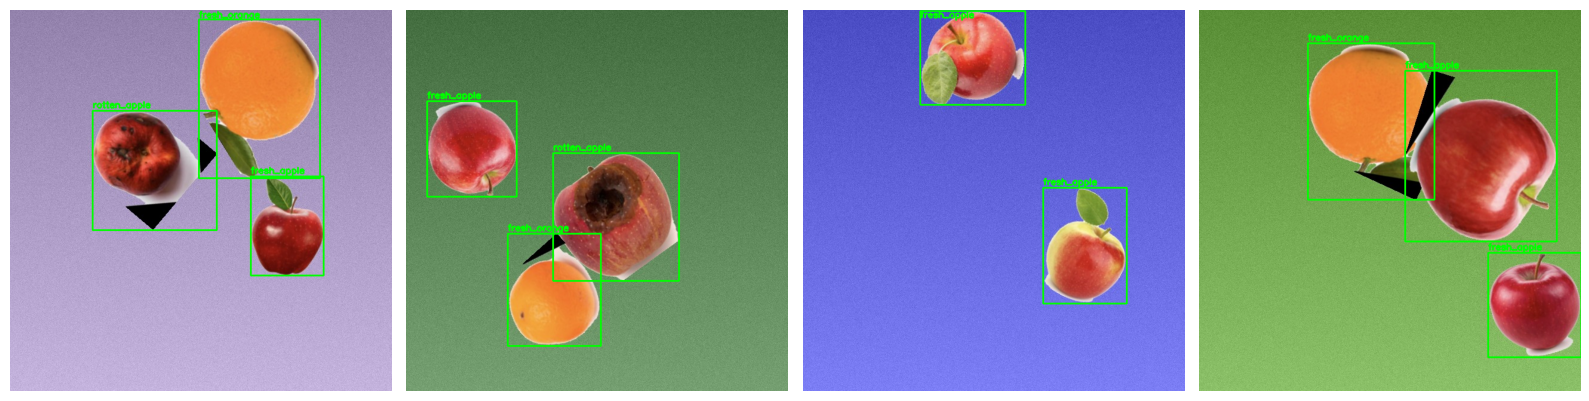

In [ ]:
def draw_yolo_bbox(image_path, label_path, ax):
    image = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]
    for class_id, x1, y1, x2, y2 in fy.yolo_boxes(label_path, width, height):
        cv2.rectangle(image, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
        cv2.putText(image, class_labels[class_id], (int(x1), max(14, int(y1) - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    ax.imshow(image)
    ax.axis("off")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, path in zip(axes, sorted(glob.glob(f"{SMOKE}/images/train/*.jpg"))[:4]):
    draw_yolo_bbox(path, path.replace("/images/", "/labels/").replace(".jpg", ".txt"), ax)
plt.tight_layout()
plt.show()

## Checking Missing Files

Checking that every image has a label file and every label file has an image.

In [ ]:
for split in ("train", "val", "test"):
    image_files = {os.path.splitext(os.path.basename(p))[0] for p in glob.glob(f"{SMOKE}/images/{split}/*.jpg")}
    label_files = {os.path.splitext(os.path.basename(p))[0] for p in glob.glob(f"{SMOKE}/labels/{split}/*.txt")}
    print(split, len(image_files), " = ", len(label_files))
    print(f"  Extra images (without corresponding labels): {image_files - label_files}")
    print(f"  Extra labels (without corresponding images): {label_files - image_files}")

train 120  =  120
  Extra images (without corresponding labels): set()
  Extra labels (without corresponding images): set()
val 30  =  30
  Extra images (without corresponding labels): set()
  Extra labels (without corresponding images): set()
test 30  =  30
  Extra images (without corresponding labels): set()
  Extra labels (without corresponding images): set()


## Checking label format

`validate_dataset` goes further. It also catches the errors that do not crash YOLO but silently damage training: class ids
out of range, pixel instead of normalised coordinates, polygon exports, and the same image in two splits. Every member can
run it on any dataset folder before training.

In [ ]:
report = fy.validate_dataset(SMOKE)
fy.assert_valid(report)

class              train     val    test
fresh_apple           71      13      18
fresh_banana          72      23      20
fresh_orange          63      21      15
rotten_apple          70      23      12
rotten_banana         78      12      21
rotten_orange         71      15      17
images               120      30      30

0 errors

0 warnings
Dataset passed: safe to train.


A check is only useful if it fails when it should. Here I break a copy of the practice set on purpose, once for each kind of mistake we could plausibly make.

In [ ]:
BROKEN = "/content/datasets/broken"
shutil.rmtree(BROKEN, ignore_errors=True)
shutil.copytree(SMOKE, BROKEN)
labels = sorted(glob.glob(f"{BROKEN}/labels/train/*.txt"))
images = sorted(glob.glob(f"{BROKEN}/images/train/*.jpg"))

open(labels[0], "w").write("6 0.5 0.5 0.2 0.2\n")               # class id that does not exist
open(labels[1], "w").write("0 320 240 50 50\n")                 # pixels, not normalised
open(labels[2], "w").write("0 0.1 0.1 0.2 0.2 0.3 0.3\n")       # polygon export
os.remove(labels[3])                                             # label lost
os.remove(images[4])                                             # image lost
shutil.copy(images[5], f"{BROKEN}/images/val/leaked.jpg")        # train image copied into val
shutil.copy(labels[5], f"{BROKEN}/labels/val/leaked.txt")

broken = fy.validate_dataset(BROKEN, near_duplicates=False)
assert len(broken["errors"]) == 6, broken["errors"]
print("\nAll 6 planted mistakes were caught.")

class              train     val    test
fresh_apple           65      15      18
fresh_banana          72      24      20
fresh_orange          60      21      15
rotten_apple          65      23      12
rotten_banana         78      13      21
rotten_orange         71      15      17
images               119      31      30

6 errors:
  - train: label composite_train_00004.txt has no matching image
  - train: composite_train_00000.txt:1 class id 6 is outside 0-5
  - train: composite_train_00001.txt:1 coordinates are not normalised to 0-1 (pixels?): '0 320 240 50 50'
  - train: composite_train_00002.txt:1 has 7 columns, expected 5 (polygon label: export as bounding boxes)
  - train: composite_train_00003.jpg has no label file (use an empty .txt for no fruit)
  - LEAKAGE across splits: identical images ['train/composite_train_00005.jpg', 'val/leaked.jpg']

0 warnings

All 6 planted mistakes were caught.


# 4. Custom object detection using YOLO

## Config file

The YAML file tells YOLO where the images are, how many classes there are, and their names. Ours is committed at the top of
the repo. It has no `path:` line on purpose, so YOLO reads the paths relative to the file and it works wherever the repo is
cloned.

In [ ]:
print(open(fy.CONFIG).read())

# YOLO dataset config for Group 18. No `path:` key on purpose: Ultralytics then resolves
# the paths below relative to this file, so it works wherever the repo is cloned.
train: datasets/fruit_freshness/images/train
val: datasets/fruit_freshness/images/val
test: datasets/fruit_freshness/images/test

nc: 6
names:
  0: fresh_apple
  1: fresh_banana
  2: fresh_orange
  3: rotten_apple
  4: rotten_banana
  5: rotten_orange



## Quick test training

Three short epochs before anyone spends GPU hours: if this runs, the folder layout, labels, config and training code all
work together. The smaller `yolov8n` model and a low image size are used here only to keep this test fast.

In [ ]:
smoke_weights = fy.train_run("smoke_test", "Daksh", data=SMOKE_CONFIG, rehearsal=True)
smoke = fy.evaluate("smoke_test", smoke_weights, data=SMOKE_CONFIG, rehearsal=True)
print({k: round(float(smoke[k]), 3) for k in fy.METRIC_COLUMNS})

New https://pypi.org/project/ultralytics/8.4.207 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/smoke.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.9, mosai

# 5. Baseline model

## Training YOLO

Choosing the data. This uses the group dataset if it is ready, and the practice set if not.

In [ ]:
REAL = fy.fetch_dataset()
if REAL:
    fy.require_gpu()
    fy.assert_valid(fy.validate_dataset())
    DATA, ROOT, REHEARSAL = fy.CONFIG, fy.DATASET, False
else:
    DATA, ROOT, REHEARSAL = SMOKE_CONFIG, SMOKE, True
    print("\n*** REHEARSAL: group dataset not ready. Numbers below only prove the code runs. Do not report them. ***")
print("Results go to:", fy.output_root(REHEARSAL))

Extracted fruit_freshness.zip (130.3 MB, splits ['test', 'train', 'val']) to /content/IAT360-Group-18/datasets/fruit_freshness
GPU: Tesla T4
class              train     val    test
fresh_apple          629      72      86
fresh_banana        1198      82      90
fresh_orange         727      51      61
rotten_apple         755      97      71
rotten_banana       1012      94      56
rotten_orange        498      49      27
images              2807     268     207

0 errors

2 warnings:
  - train: 7d4d5427cd475e98.txt:3 is a duplicate box
  - possible leakage, near-identical images across splits: ['train/cccd677b3e64a2b4.jpg', 'val/38472bc6f3d4f2f3.jpg']
Dataset passed: safe to train.
Results go to: /content/drive/MyDrive/IAT360-Group 18/results


We start from `yolov8s`, the small pretrained (on the COCO dataset) model used in the course tutorial.

**Why the baseline writes out its optimizer.** With YOLO's default `optimizer=auto`, the training log says it is
*"ignoring lr0"*, so Philip's learning-rate runs would all train the same model. For a dataset our size, `auto` picks
AdamW with `lr0=0.001`, `momentum=0.9` and `warmup_bias_lr=0`, so `BASELINE` sets those explicitly. Behaviour stays the
same and `lr0` starts working.

**Other settings** are YOLO defaults (`imgsz=640`, `batch=16`). Epochs are 50 rather than 100, with `patience=20`, to fit
13+ runs on free Colab GPUs before the deadline. See the [YOLO train docs](https://docs.ultralytics.com/modes/train/#train-settings)
for what each hyperparameter does.

In [ ]:
settings = fy.run_settings(rehearsal=REHEARSAL)
model = YOLO(settings.pop("model"))  # pretrained model
print(settings)

{'epochs': 50, 'patience': 20, 'imgsz': 640, 'batch': 16, 'optimizer': 'AdamW', 'lr0': 0.001, 'momentum': 0.9, 'warmup_bias_lr': 0.0, 'seed': 0, 'deterministic': True}


The detailed architecture of the model can be seen from:

In [ ]:
model

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(96, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0

Training. A finished baseline is not retrained if this cell is run again.

In [ ]:
baseline_weights = fy.weights_path("baseline", REHEARSAL)
if not baseline_weights.exists():
    model.train(data=str(DATA), project=str(fy.runs_dir(REHEARSAL)), name="baseline", exist_ok=True, **settings)
    baseline_weights = fy.record_run("baseline", "Daksh", model, rehearsal=REHEARSAL)

New https://pypi.org/project/ultralytics/8.4.207 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/IAT360-Group-18/config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, m

## Evaluation Metrics

[This guide](https://docs.ultralytics.com/guides/yolo-performance-metrics/) explains YOLO's performance metrics.

**Choosing the right metrics.** Our use case is finding rotten fruit before it spreads, so a missed rotten fruit costs more
than a false alarm. **Recall on the rotten classes** matters most, alongside mAP for overall quality.

- mAP: a broad assessment of model performance.
- Precision: how many flagged fruit were really that class. Low precision means staff check good fruit for nothing.
- Recall: how many real fruit were found. Low rotten recall means rot stays in the bin.
- F1 score: the balance between precision and recall.

In [ ]:
model = YOLO(str(baseline_weights))
metrics = model.val(data=str(DATA), imgsz=fy.trained_imgsz("baseline", REHEARSAL),
                    project=str(fy.runs_dir(REHEARSAL)), name="baseline_val", exist_ok=True)
print("mAP50-95:", metrics.box.map)
print("mAP50:   ", metrics.box.map50)
print("mAP75:   ", metrics.box.map75)
print("per class mAP50-95:", dict(zip(fy.CLASS_NAMES, metrics.box.maps.round(3).tolist())))
print("precision:", metrics.box.mp)
print("recall:   ", metrics.box.mr)

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1345.4±483.1 MB/s, size: 36.6 KB)
val: Scanning /content/IAT360-Group-18/datasets/fruit_freshness/labels/val.cache... 268 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 268/268 74.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 3.4it/s 5.0s
                   all        268        445       0.93      0.947      0.973      0.834
           fresh_apple         59         72      0.983      0.972       0.99       0.85
          fresh_banana         39         82      0.848       0.95      0.945      0.761
          fresh_orange         45         51      0.921       0.98      0.979      0.888
          rotten_apple         84         97      0.969      0.956      0.987      0.931
         rotten

The rubric also asks for accuracy and F1, and our use case needs rotten-class results, so `evaluate` adds these:

- `accuracy`: correct boxes / (correct + wrong class + missed + false alarms), from the confusion matrix at confidence 0.25, the threshold a deployed system would use. Detection has no true negatives, so this is the closest equivalent. mAP is measured separately at YOLO's default low confidence, because it sweeps every threshold.
- `rotten_recall`: average recall of the three rotten classes.
- `rotten_flag_recall`: share of rotten fruit flagged as rotten of *any* type. Calling a rotten apple a rotten orange still gets it removed from the bin.

**Drive workaround.** After training, Colab stopped seeing files in the shared folder that were on Drive (`baseline.pt`
was there, at 22.5 MB, but `os.path.exists` said False even after remounting). The next three cells check for the file,
remount Drive, then fall back to the same weights downloaded by their Drive file id. Nothing was retrained.

In [ ]:
import os
print(os.path.exists(baseline_weights), baseline_weights)

False /content/drive/MyDrive/IAT360-Group 18/results/weights/baseline.pt


In [ ]:
drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)
print(os.path.exists(baseline_weights))

Mounted at /content/drive
False


In [ ]:
from pathlib import Path
candidates = [baseline_weights,
              *map(Path, glob.glob("/content/drive/.shortcut-targets-by-id/*/IAT360-Group 18/results/weights/baseline.pt")),
              fy.runs_dir() / "baseline" / "weights" / "best.pt"]
found = next((p for p in candidates if p.exists()), None)
if found is None:
    # Same file, downloaded straight from the shared folder by its Drive id
    !gdown -q 1Nra4lF9Pfh0cw4xfz6Gd6BoiU7cjSpUe -O /content/baseline.pt
    found = Path("/content/baseline.pt")
baseline_weights = found
print("Using", baseline_weights, baseline_weights.exists())

Using /content/drive/MyDrive/IAT360-Group 18/results/runs/baseline/weights/best.pt True


In [ ]:
baseline = fy.evaluate("baseline", baseline_weights, data=DATA, rehearsal=REHEARSAL)
display(pd.DataFrame([{k: baseline[k] for k in fy.METRIC_COLUMNS}], index=["baseline"]).round(3))
display(pd.DataFrame(baseline["per_class"]).T.round(3))
print({k: baseline[k] for k in ("rotten_called_fresh", "rotten_missed", "false_alarms")})

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1569.9±862.0 MB/s, size: 38.4 KB)
val: Scanning /content/IAT360-Group-18/datasets/fruit_freshness/labels/val.cache... 268 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 268/268 56.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 3.2it/s 5.4s
                   all        268        445       0.93      0.947      0.973      0.834
Speed: 1.9ms preprocess, 10.6ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/drive/.shortcut-targets-by-id/1tg_FgsqtWY2XL1AYXk46Vg75mA5M8r6N/IAT360-Group 18/results/evals/baseline_val
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 2

,accuracy,precision,recall,f1,mAP50,mAP50_95,rotten_recall,rotten_flag_recall
baseline,0.866,0.93,0.947,0.938,0.973,0.834,0.926,0.95


,precision,recall,f1,mAP50,mAP50_95
fresh_apple,0.983,0.972,0.977,0.990,0.850
fresh_banana,0.848,0.950,0.896,0.945,0.761
fresh_orange,0.921,0.980,0.950,0.979,0.888
rotten_apple,0.969,0.956,0.962,0.987,0.931
rotten_banana,0.908,0.862,0.884,0.951,0.658
rotten_orange,0.949,0.959,0.954,0.984,0.917


{'rotten_called_fresh': 3.0, 'rotten_missed': 9.0, 'false_alarms': 48.0}


Showing the confusion matrix and training curves that YOLO saved.

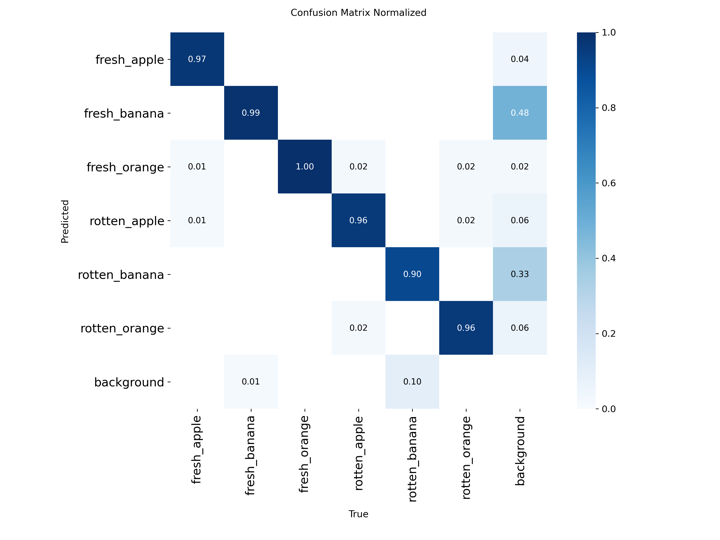

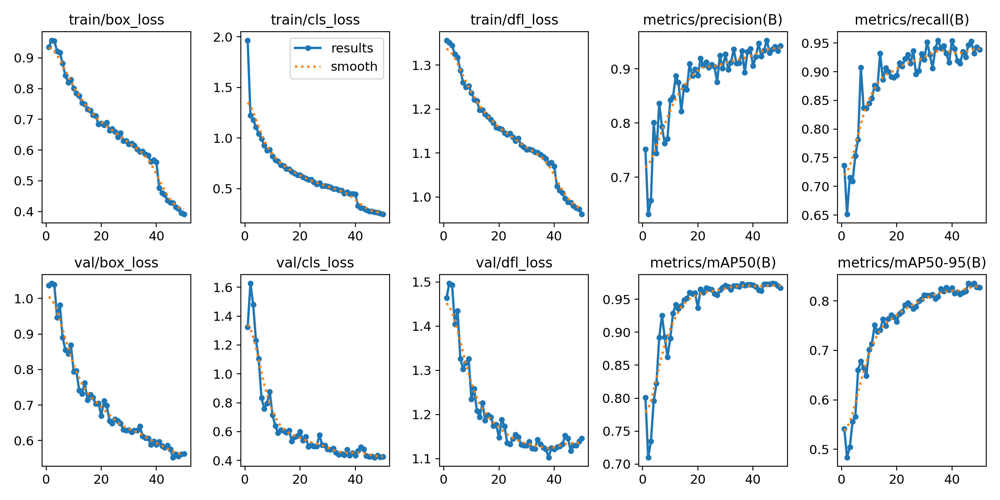

In [ ]:
figures = fy.output_root(REHEARSAL) / "figures"
display(Image.open(figures / "baseline_val" / "confusion_matrix_normalized.png").resize((720, 540)))
display(Image.open(figures / "baseline" / "results.png").resize((1000, 500)))

Is the model underfitting or overfitting? The train and validation losses give the evidence.

In [ ]:
fy.fit_report("baseline", rehearsal=REHEARSAL)

{'epochs_run': 50,
 'best_epoch': 46,
 'final_train_loss': 0.6371,
 'final_val_loss': 0.9889,
 'lowest_val_loss': 0.9821,
 'val_loss_rise_after_best': 0.0068,
 'train_val_gap': 0.3519,
 'reading': 'val loss flattened with train loss: reasonable fit'}

Paste-ready numbers for the report, so the write-up uses exactly what was measured.

In [ ]:
fit = fy.fit_report("baseline", rehearsal=REHEARSAL)
print(pd.DataFrame([{k: baseline[k] for k in fy.METRIC_COLUMNS}], index=["baseline"]).round(3).to_markdown())
print()
print(pd.DataFrame(baseline["per_class"]).T.round(3).to_markdown())
print(f"\nFit: {fit['reading']} (lowest val loss at epoch {fit['best_epoch']} of {fit['epochs_run']}).")
print(f"Rotten fruit called fresh: {baseline['rotten_called_fresh']:.0f}. "
      f"Rotten fruit missed: {baseline['rotten_missed']:.0f}. False alarms: {baseline['false_alarms']:.0f}.")

|          |   accuracy |   precision |   recall |    f1 |   mAP50 |   mAP50_95 |   rotten_recall |   rotten_flag_recall |
|:---------|-----------:|------------:|---------:|------:|--------:|-----------:|----------------:|---------------------:|
| baseline |      0.866 |        0.93 |    0.947 | 0.938 |   0.973 |      0.834 |           0.926 |                 0.95 |

|               |   precision |   recall |    f1 |   mAP50 |   mAP50_95 |
|:--------------|------------:|---------:|------:|--------:|-----------:|
| fresh_apple   |       0.983 |    0.972 | 0.977 |   0.99  |      0.85  |
| fresh_banana  |       0.848 |    0.95  | 0.896 |   0.945 |      0.761 |
| fresh_orange  |       0.921 |    0.98  | 0.95  |   0.979 |      0.888 |
| rotten_apple  |       0.969 |    0.956 | 0.962 |   0.987 |      0.931 |
| rotten_banana |       0.908 |    0.862 | 0.884 |   0.951 |      0.658 |
| rotten_orange |       0.949 |    0.959 | 0.954 |   0.984 |      0.917 |

Fit: val loss flattened with train lo

### My baseline results

| Metric | Baseline |
|---|---|
| mAP@0.5:0.95 | **0.834** |
| mAP@0.5 | 0.973 |
| Precision / recall / F1 | 0.930 / 0.947 / 0.938 |
| Accuracy (confidence 0.25) | 0.866 |
| Rotten recall (mean of 3 classes) | 0.926 |
| Rotten fruit flagged as rotten of any type | 95% |

Validation set: 268 images, 445 fruit. Of the rotten fruit, 3 were called fresh and 9 were missed; there were 48 false alarms.

**Weakest class: rotten banana** (mAP@0.5:0.95 0.658, recall 0.862). Its mAP@0.5 is still 0.951, so the model finds rotten
bananas but draws loose boxes around them. The failed examples above show why: in dark, overlapping bunches the model boxes
bananas that the annotator skipped under our "visible from end to end" rule, and the boxes overlap. Bananas also cause most
false alarms: of predictions with no matching fruit, 48% were fresh banana and 33% rotten banana (background column of the
normalized confusion matrix). The one cross-fruit error type is shrivelled yellow rotten apples called fresh orange.

**Fit: a reasonable fit, with the first signs of overfitting in the last four epochs.** For 40 epochs, validation loss
tracked training loss closely (gap -0.11 at epoch 10, +0.02 at epoch 40). At epoch 41 YOLO switches mosaic augmentation off,
so training images become easier and training loss drops sharply (1.00 to 0.81), which opens a gap of about 0.26. That jump
is the augmentation change, not overfitting: validation loss kept improving and reached its lowest value (0.982) at epoch 46,
where mAP@0.5:0.95 also peaked (0.836). After epoch 46, training loss kept falling (0.70 to 0.64) while validation loss stopped
improving (0.989 at epoch 50), and the gap widened to 0.35. The saved `best.pt` is the epoch-46 model, so this does not affect
the reported scores.

**Concrete fixes**
- Rotten bananas: add real photos of bunches and relabel the existing ones with one consistent rule, since the label ambiguity
  costs more here than model capacity.
- Rotten apples called fresh oranges: more rotten-apple examples with yellow skin, and keep colour augmentation limited
  (Jasper's augmentation test), because colour is the main cue.
- Overfitting: 50 epochs is enough for batch 16, and training longer would mostly widen the gap. Keep early stopping
  (`patience`) and the best checkpoint. If more epochs are needed, add data rather than epochs, and consider stronger
  regularisation (weight decay, or keeping mosaic on longer with a smaller `close_mosaic`).
- Settings still improving at epoch 50 (batch 8, 32 and 64, see Section 6) are the exception: they would need longer runs
  to be compared fairly.
- Domain gap: these scores come from public images and generated composites. Lavanya's evaluation on our own store photos is
  the honest test and is expected to be lower.

## Correct and incorrect examples

Green boxes are the true labels, orange boxes are predictions.

229 images fully correct, 39 with at least one mistake


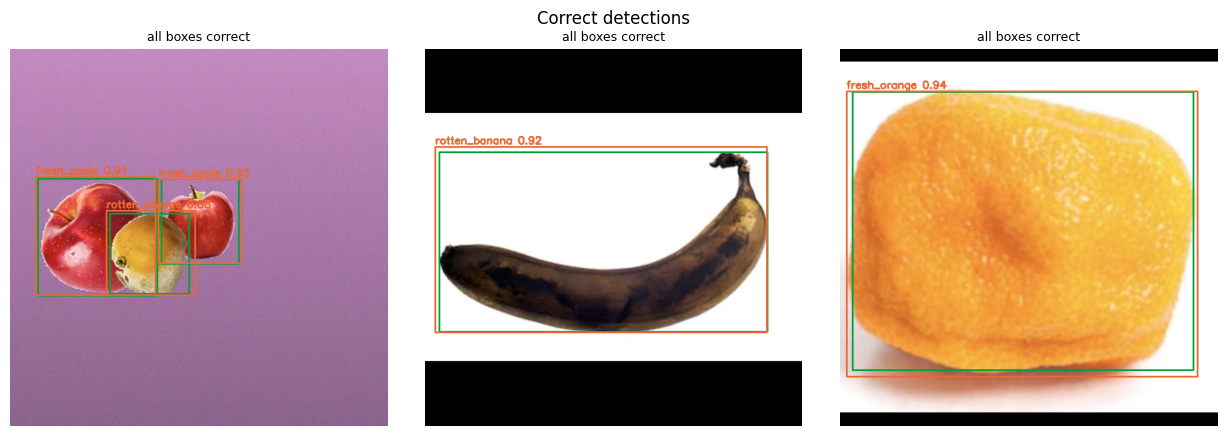

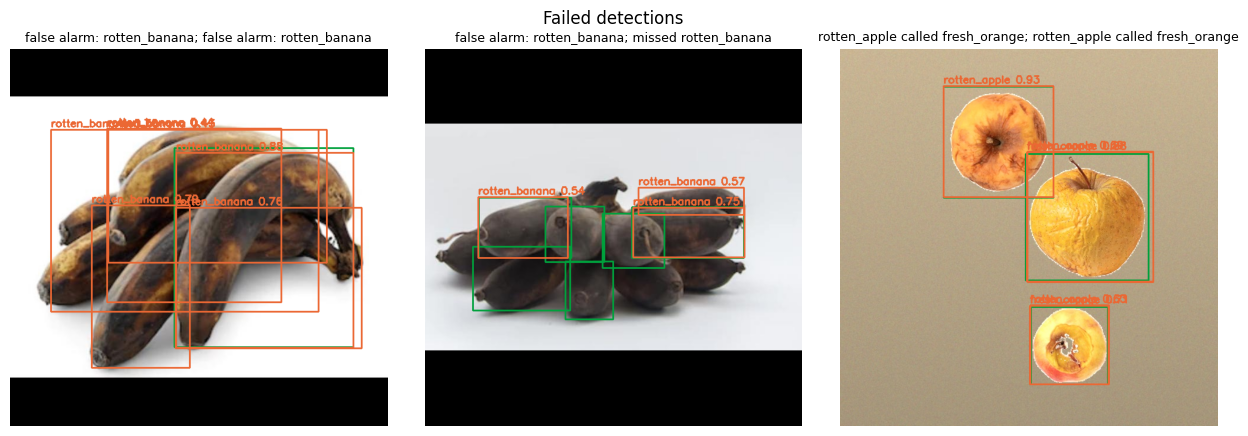

In [ ]:
scored = fy.score_images(baseline_weights, root=ROOT, split="val")
wrong = sum(bool(s["problems"]) for s in scored)
print(f"{len(scored) - wrong} images fully correct, {wrong} with at least one mistake")
fy.show_examples(scored, correct=True, n=3, save_to=figures / "baseline" / "examples_correct.png"); plt.show()
fy.show_examples(scored, correct=False, n=3, save_to=figures / "baseline" / "examples_incorrect.png"); plt.show()

## Prediction

Running the saved model on a real photo that it never trained on, then showing the stored image, as the tutorial does.

100%|██████████| 28.4M/28.4M [00:01<00:00, 23.2MB/s]

Extracting files...



image 1/1 /root/.cache/kagglehub/datasets/mbkinaci/fruit-images-for-object-detection/versions/1/test_zip/test/mixed_21.jpg: 448x640 1 fresh_banana, 6 fresh_oranges, 13.6ms
Speed: 2.2ms preprocess, 13.6ms inference, 1.4ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/drive/.shortcut-targets-by-id/1tg_FgsqtWY2XL1AYXk46Vg75mA5M8r6N/IAT360-Group 18/results/runs/baseline_predict


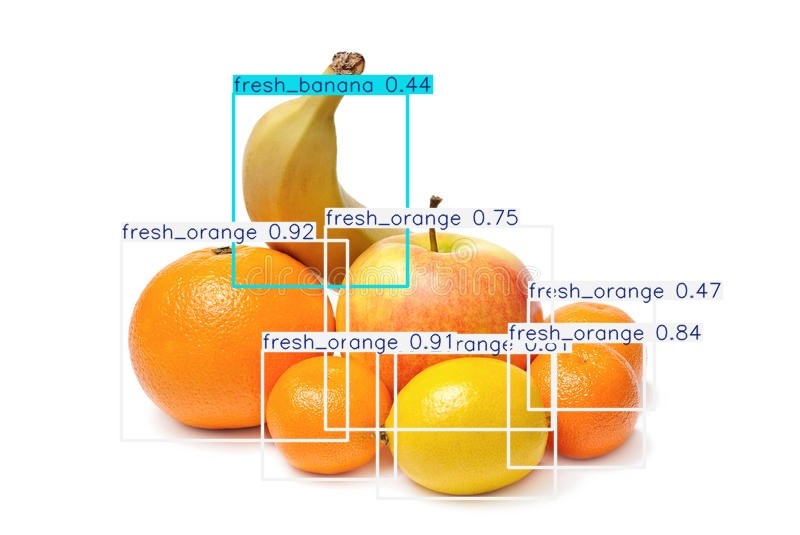

In [ ]:
photos = kagglehub.dataset_download("mbkinaci/fruit-images-for-object-detection")
photo = sorted(glob.glob(f"{photos}/test_zip/test/mixed_*.jpg"))[0]

model = YOLO(str(baseline_weights))  # load the saved model
results = model(photo, save=True, project=str(fy.runs_dir(REHEARSAL)), name="baseline_predict", exist_ok=True)
Image.open(os.path.join(results[0].save_dir, os.path.basename(photo)))

# 6. Batch size tuning

Baseline `batch=16`, tuned at **8, 32 and 64**.

**What to expect.** YOLO accumulates gradients up to a nominal batch of 64 (`nbs=64`), so the weights update about every
64 images whichever batch we choose: 8 x 8, 16 x 4, 32 x 2, 64 x 1. Batch size then mainly changes BatchNorm statistics and
speed rather than the size of each update, so the differences may be small. The table records the effective batch for each
run, so this can be checked rather than assumed.

**Is a difference real?** The baseline fixes `seed=0`, so every run is repeatable, but a different seed would still
shuffle and augment the data differently. I train the baseline once more with `seed=1` (`baseline_seed1`) and use the
gap between the two as the run-to-run noise. A batch size only counts as better or worse if its gap to the baseline is
larger than that. One repeat is a rough estimate, so gaps close to it are treated as a tie. Other members can use the
same number through `fy.seed_noise`.

In [ ]:
OWNER = "Daksh"
PARAM, VALUES = fy.TUNING_PLAN[OWNER]
RUNS = [f"{PARAM}_{v}" for v in VALUES]

for name, value in zip(RUNS, VALUES):
    weights = fy.train_run(name, OWNER, overrides={PARAM: value}, data=DATA, rehearsal=REHEARSAL)
    fy.evaluate(name, weights, data=DATA, rehearsal=REHEARSAL)

# Run-to-run noise: the baseline again, changing only the random seed.
noise_weights = fy.train_run("baseline_seed1", OWNER, overrides={"seed": 1}, data=DATA, rehearsal=REHEARSAL)
fy.evaluate("baseline_seed1", noise_weights, data=DATA, rehearsal=REHEARSAL)

GPU: Tesla T4
config.yaml: 6 classes, order matches.
New https://pypi.org/project/ultralytics/8.4.207 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/IAT360-Group-18/config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max

{'name': 'baseline_seed1',
 'split': 'val',
 'conf': 0.25,
 'true_boxes': 445,
 'precision': 0.9279907674728355,
 'recall': 0.9543450967252868,
 'f1': 0.9409834404035149,
 'mAP50': 0.9757879710543856,
 'mAP50_95': 0.822644062378116,
 'rotten_recall': 0.9439204503911677,
 'per_class': {'fresh_apple': {'precision': 0.9715375073061632,
   'recall': 0.9722222222222222,
   'f1': 0.9718797441642778,
   'mAP50': 0.9931119106119105,
   'mAP50_95': 0.8286094341915134},
  'fresh_banana': {'precision': 0.8373404237511335,
   'recall': 0.9416948500932504,
   'f1': 0.8864570325437132,
   'mAP50': 0.9546637710635664,
   'mAP50_95': 0.7504201249660605},
  'fresh_orange': {'precision': 0.9911670406779324,
   'recall': 0.9803921568627451,
   'f1': 0.9857501555455611,
   'mAP50': 0.9944444444444444,
   'mAP50_95': 0.8870553854650053},
  'rotten_apple': {'precision': 0.9682668549345338,
   'recall': 0.9381443298969072,
   'f1': 0.9529676147638209,
   'mAP50': 0.9854091125008353,
   'mAP50_95': 0.92508158

The same Drive problem hid `baseline__val.json` and `baseline__train.json` from Colab (see the "Colab sees" line). This
cell downloads the ten metrics files of this section by their Drive ids and builds the comparison table from them.

In [ ]:
import subprocess
from pathlib import Path
print("Colab sees:", sorted(p.name for p in (fy.output_root() / "metrics").glob("*__val.json")))

ids = {"baseline__train.json": "1Zwqc7dzqh1vo-DAxiPxSPA4wkW9PoPJe", "baseline__val.json": "1gCzyESKRzCUJxhR3ObKHezvtm0i2I_1D",
       "baseline_seed1__train.json": "1nTzpBlVpUTnv9lSWtrnzhXnv5zhm50qB", "baseline_seed1__val.json": "1cRt9l87-Ufq9LufsJYvq4hANKiM5-8nF",
       "batch_8__train.json": "1_UTkKaVrqulZ6Myx1OcpHDA40wZYTocQ", "batch_8__val.json": "1W8_IACN93kd-j08FFz-4FN4u4GsD2q7c",
       "batch_32__train.json": "1LBfM-niEVjdRb_-MryZvXMzJ4efTW16D", "batch_32__val.json": "1JWFabmANqsobJbdtrmeo4LuDAaei39pL",
       "batch_64__train.json": "1DxsnroQH1xemHexr7dhZelZszANVqSnJ", "batch_64__val.json": "1uAvlrGoycUJImAJAvBw5hGTeCTFVm3lA"}
mirror = Path("/content/metrics_mirror")
(mirror / "metrics").mkdir(parents=True, exist_ok=True)
for name, fid in ids.items():
    subprocess.run(["gdown", "-q", fid, "-O", str(mirror / "metrics" / name)], check=True)

real_root = fy.output_root
fy.output_root = lambda rehearsal=False: mirror
try:
    table = fy.compare_runs(names=["baseline", "baseline_seed1"] + RUNS, rehearsal=REHEARSAL)
finally:
    fy.output_root = real_root

Colab sees: ['baseline_seed1__val.json', 'batch_32__val.json', 'batch_64__val.json', 'batch_8__val.json', 'lr0_0.0003__val.json']


,owner,changed,accuracy,precision,recall,f1,mAP50,mAP50_95,rotten_recall,rotten_flag_recall,minutes,effective_batch,mAP50_95_vs_baseline
run,,,,,,,,,,,,,
baseline,Daksh,none,0.8661,0.9296,0.9467,0.9381,0.9726,0.8341,0.9257,0.9500,41.1,64,0.0000
baseline_seed1,Daksh,seed=1,0.8597,0.9280,0.9543,0.9410,0.9758,0.8226,0.9439,0.9708,46.7,64,-0.0115
batch_32,Daksh,batch=32,0.9002,0.9395,0.9699,0.9545,0.9734,0.8226,0.9577,0.9708,41.7,64,-0.0115
batch_64,Daksh,batch=64,0.8598,0.9262,0.9500,0.9379,0.9661,0.8307,0.9402,0.9500,48.4,64,-0.0035
batch_8,Daksh,batch=8,0.8755,0.9427,0.9498,0.9463,0.9755,0.8249,0.9452,0.9667,49.3,64,-0.0092


Seed noise on mAP@0.5:0.95: 0.0115

batch_8    -0.0092  within seed noise, so a tie
batch_32   -0.0115  larger than seed noise
batch_64   -0.0035  within seed noise, so a tie


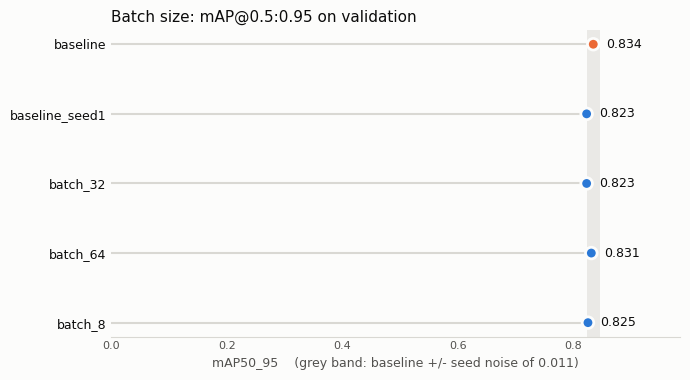

batch_8 {'epochs_run': 50, 'best_epoch': 48, 'final_train_loss': 0.6518, 'final_val_loss': 0.9604, 'lowest_val_loss': 0.9517, 'val_loss_rise_after_best': 0.0086, 'train_val_gap': 0.3086, 'reading': 'val loss flattened with train loss: reasonable fit'}
batch_32 {'epochs_run': 50, 'best_epoch': 50, 'final_train_loss': 0.6244, 'final_val_loss': 1.0088, 'lowest_val_loss': 1.0088, 'val_loss_rise_after_best': 0.0, 'train_val_gap': 0.3844, 'reading': 'val loss still falling at the end: likely underfit, train longer'}
batch_64 {'epochs_run': 50, 'best_epoch': 50, 'final_train_loss': 0.6053, 'final_val_loss': 1.085, 'lowest_val_loss': 1.085, 'val_loss_rise_after_best': 0.0, 'train_val_gap': 0.4797, 'reading': 'val loss still falling at the end: likely underfit, train longer'}


In [ ]:
display(table)
noise = fy.seed_noise(table)
print(f"Seed noise on mAP@0.5:0.95: {noise:.4f}\n")
for name in RUNS:
    gap = table.loc[name, "mAP50_95_vs_baseline"]
    verdict = "larger than seed noise" if abs(gap) > noise else "within seed noise, so a tie"
    print(f"{name:<10} {gap:+.4f}  {verdict}")

title = "Batch size: mAP@0.5:0.95 on validation" + (" (REHEARSAL, not results)" if REHEARSAL else "")
fy.plot_comparison(table, title, noise=noise, save_to=figures / "tuning_batch.png")
plt.show()
for name in RUNS:
    print(name, fy.fit_report(name, rehearsal=REHEARSAL))

### My results

| Run | mAP@0.5:0.95 | Gap to baseline | Reading | F1 | Accuracy | Rotten missed | Train minutes |
|---|---|---|---|---|---|---|---|
| baseline (batch 16) | **0.834** | | | 0.938 | 0.866 | 9 | 41.1 |
| baseline_seed1 | 0.823 | -0.012 | this gap is the seed noise | 0.941 | 0.860 | 6 | 46.7 |
| batch 8 | 0.825 | -0.009 | tie | 0.946 | 0.876 | 6 | 49.3 |
| batch 32 | 0.823 | -0.012 | tie | 0.954 | 0.900 | 6 | 41.7 |
| batch 64 | 0.831 | -0.003 | tie | 0.938 | 0.860 | 11 | 48.4 |

**No batch size beat the baseline.** Retraining the baseline with only the seed changed moved mAP@0.5:0.95 by 0.0115, and
every batch size landed within that distance of the baseline. The verdict printed above calls batch 32 "larger than seed
noise", but its gap equals the noise to 4 decimal places (0.0115 against 0.0115), so it is a tie.

This matches the prediction at the top of this section. YOLO accumulates gradients up to 64 images (`nbs=64`), so every run had
an effective batch of 64 and updated its weights equally often. Batch size then only changes BatchNorm statistics and speed.
All four sizes fitted in the T4's memory, including 64.

Two things worth noting without over-reading them:
- Batch 32 had the best F1 (0.954) and accuracy (0.900), with the fewest false alarms (36 against 48), but one run per value
  cannot separate that from noise.
- Batch 8, 32 and 64 were all still improving at epoch 50 (best epoch = last epoch). Batch 64 rose from 0.808 at epoch 40
  to 0.831 at epoch 50. With longer training the larger batches might catch up or pass the baseline. This was not tested.

**Value for the final model: keep `batch=16`.**

# 7. Figures for the slides and GitHub

Every run's plots and confusion matrices are in one folder per run, so all slides use the same figures. On real runs this
is the shared Drive folder `IAT360-Group 18/results/figures`.

In [ ]:
for folder in sorted(p for p in figures.iterdir() if p.is_dir()):
    print(f"{folder.name:<20}", len(list(folder.glob("*.png"))), "plots")

baseline             9 plots
baseline_seed1       7 plots
baseline_seed1_val   6 plots
baseline_val         6 plots
batch_32             7 plots
batch_32_val         6 plots
batch_64             7 plots
batch_64_val         6 plots
batch_8              7 plots
batch_8_val          6 plots
lr0_0.0003           7 plots
lr0_0.0003_val       6 plots


Which runs from the whole group are trained, evaluated and have their plots in the shared folder. Anything at 0 is
still missing from the slides.

In [ ]:
fy.run_status(rehearsal=REHEARSAL)

,owner,trained,evaluated,training_plots,eval_plots
run,,,,,
baseline,Daksh,False,False,9,6
baseline_seed1,Daksh,True,True,7,6
lr0_0.0003,Philip,True,True,7,6
lr0_0.003,Philip,False,False,0,0
lr0_0.01,Philip,False,False,0,0
imgsz_416,Jasper,False,False,0,0
imgsz_512,Jasper,False,False,0,0
imgsz_800,Jasper,False,False,0,0
batch_8,Daksh,True,True,7,6


The rubric needs results visible on GitHub. After a real run, this makes one zip in the repo's layout: unzip it at the top of the repo and commit.

In [ ]:
if REAL:
    fy.package_results(["baseline", "baseline_seed1"] + RUNS)
else:
    print("Rehearsal: nothing to publish.")

Unzip at the top of the repo, then commit: /content/drive/MyDrive/IAT360-Group 18/results/results_for_github.zip


# 8. Notes for my report section

See [Daksh_Shortcomings_and_Challenges.md](https://github.com/laoneya31/IAT360-Group-18/blob/main/report/Daksh_Shortcomings_and_Challenges.md).
Update it with real numbers after Sections 5 and 6 have run on the group dataset.